In [1]:
import matplotlib.pyplot as plt
from astropy.io import fits
import numpy as np

In [4]:
l = ["../../course_assignments/homework10/M13_0001.fits", "../../course_assignments/homework10/M13_0002.fits", "../../course_assignments/homework10/M13_0003.fits", "../../course_assignments/homework10/M13_0004.fits", "../../course_assignments/homework10/M13_0005.fits"]
h = []
d = []
for a in l:
    with fits.open(a) as hdul:
        h.append(hdul[0].header)
        d.append(hdul[0].data)

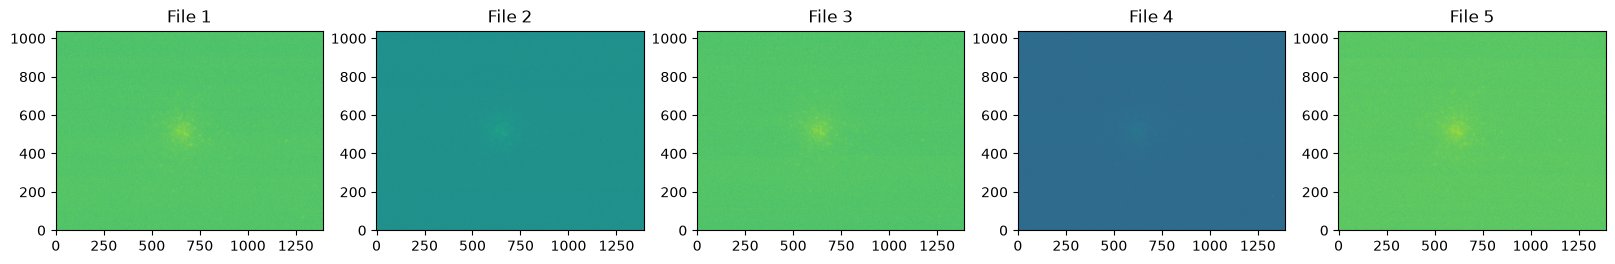

In [6]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i in range(5):
    axes[i].imshow(d[i], origin="lower")
    axes[i].set_title(f"File {i+1}")
plt.show()

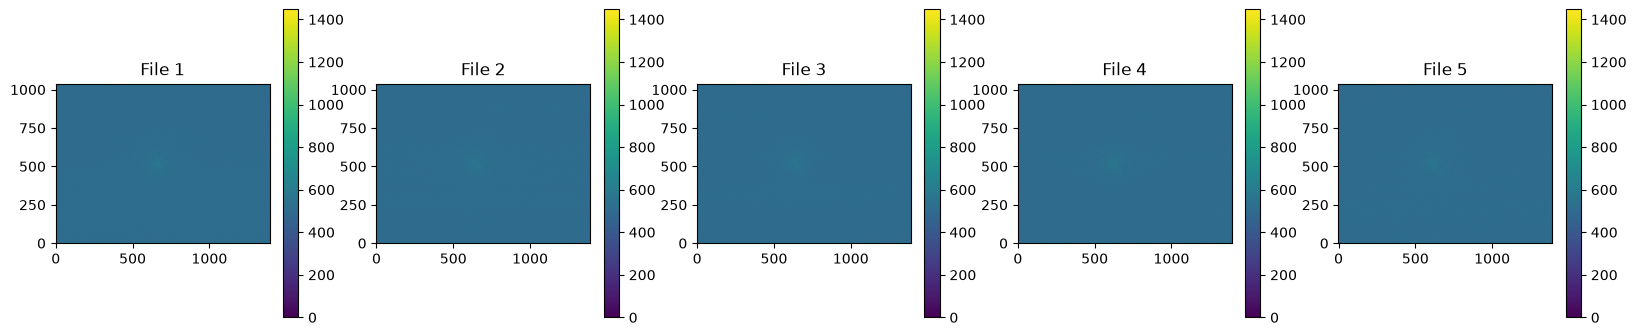

In [7]:
vmin = np.min([np.min(data) for data in d])
vmax = np.max([np.max(data) for data in d])

fig2, axes2 = plt.subplots(1, 5, figsize=(20, 4))
for i in range(5):
    im = axes2[i].imshow(d[i], origin="lower", vmin=vmin, vmax=vmax)
    axes2[i].set_title(f"File {i+1}")
    fig2.colorbar(im, ax=axes2[i])
plt.show()

Image 1: Mean = 510.47, Median = 512.00
Image 2: Mean = 509.75, Median = 511.00
Image 3: Mean = 508.05, Median = 510.00
Image 4: Mean = 507.91, Median = 509.00
Image 5: Mean = 508.79, Median = 510.00


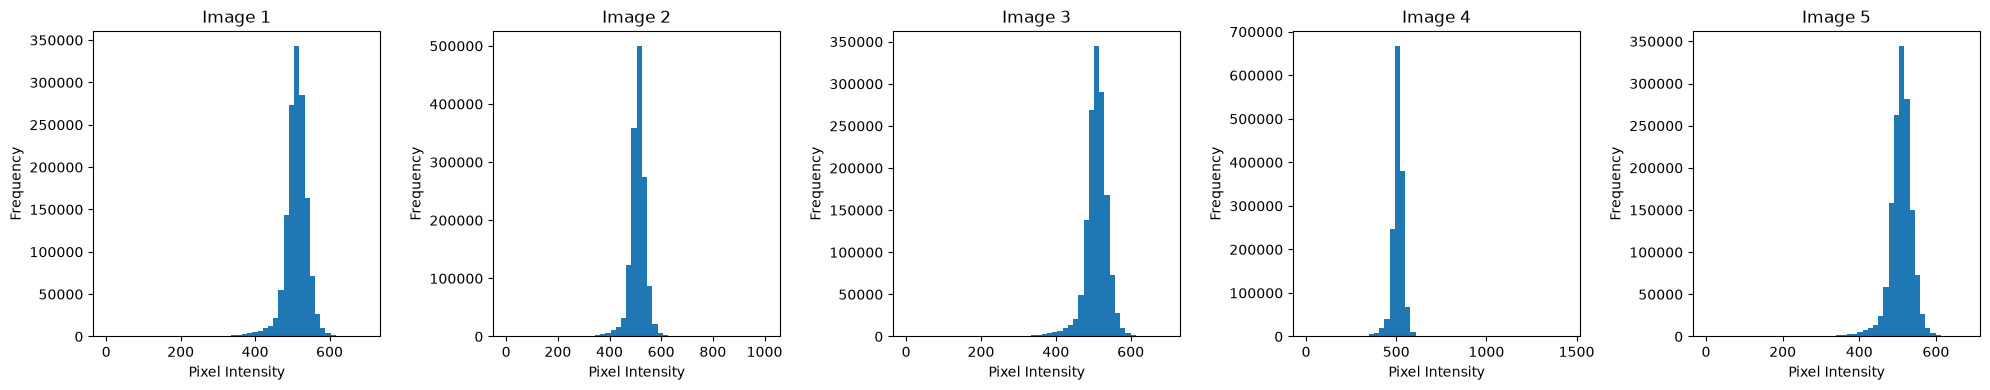

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for i in range(len(d)):
    axes[i].hist(d[i].ravel(), bins=50)
    axes[i].set_title(f"Image {i+1}")
    axes[i].set_xlabel("Pixel Intensity")
    axes[i].set_ylabel("Frequency")
    img_mean = np.mean(d[i])
    img_median = np.median(d[i])
    print(f"Image {i+1}: Mean = {img_mean:.2f}, Median = {img_median:.2f}")

plt.tight_layout()
plt.show()

In [9]:
# x: pixel intensity y: frequency
# 50 bins (intervals) for pixels to fall in
# centered around background
# very narrow spread
# as printed

In [10]:
stacked_data = np.array(d)
combined_image = np.median(stacked_data, axis=0)
combined_median = np.median(combined_image)
print(f"New median pixel intensity of combined image: {combined_median:.2f}")

New median pixel intensity of combined image: 510.00


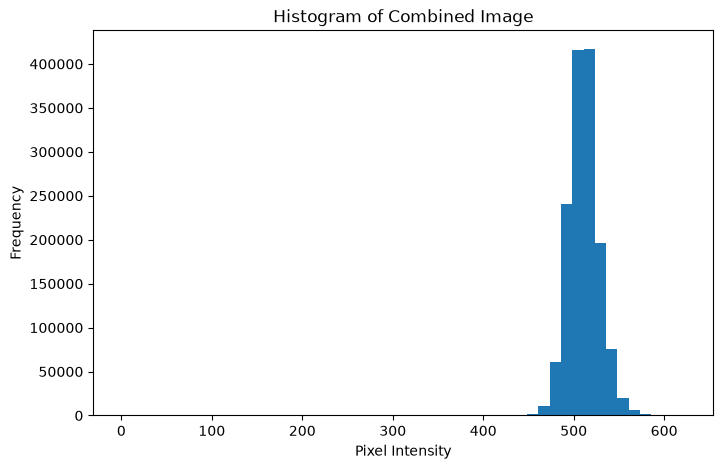

In [11]:
plt.figure(figsize=(8, 5))
counts, bins, patches = plt.hist(combined_image.ravel(), bins=50)
plt.title("Histogram of Combined Image")
plt.xlabel("Pixel Intensity")
plt.ylabel("Frequency")
plt.show()

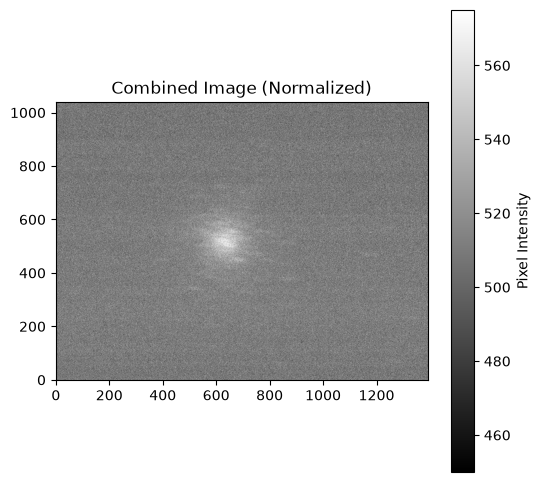

In [12]:
vmin_val = 450
vmax_val = 575

plt.figure(figsize=(6, 6))
# Plot using the specific vmin and vmax
plt.imshow(combined_image, origin="lower", vmin=vmin_val, vmax=vmax_val, cmap='gray')
plt.colorbar(label="Pixel Intensity")
plt.title("Combined Image (Normalized)")
plt.show()

In [13]:
# much smoother as the background is normalized 

In [14]:
fits.writeto("combined.fits", combined_image, overwrite=True)